In [1]:
import os, re, json, random
from pathlib import Path
from collections import Counter
from typing import Optional
import arff as liac_arff
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, RobustScaler
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.metrics import accuracy_score
import joblib
from imblearn.over_sampling import SMOTE

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import numpy as np
import pandas as pd
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.cluster import DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.io import arff as scipy_arff_local
from sklearn.metrics import balanced_accuracy_score



SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

ARFF_DIR = Path("../RLFINALFINAL/data-extra-chat-brows-ft-p2p").resolve()
if not ARFF_DIR.exists():
    raise FileNotFoundError(f"ARFF_DIR not found: {ARFF_DIR}")

def _sort_key(p: Path):
    s = p.stem
    nums = re.findall(r"\d+", s)
    return (re.sub(r"\d+", "_", s), tuple(map(int, nums)) if nums else (-1,))

ARFF_PATHS = sorted(ARFF_DIR.glob("*.arff"), key=_sort_key)
print(f"Found {len(list(ARFF_PATHS))} ARFF files in {ARFF_DIR}")
if not ARFF_PATHS:
    raise FileNotFoundError(f"No .arff files in {ARFF_DIR}")

ART_DIR = Path("./deepv14").resolve()
for sub in ("models", "scalers", "logs"):
    (ART_DIR / sub).mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
print("Versions -> torch:", torch.__version__, "| numpy:", np.__version__, "| pandas:", pd.__version__)
DEVICE


Found 11 ARFF files in /mnt/d/FYP/RLFINALFINAL/data-extra-chat-brows-ft-p2p
Device: cuda
Versions -> torch: 2.5.1+cu121 | numpy: 2.3.3 | pandas: 2.3.2


device(type='cuda')

In [2]:
def _decode_bytes(df: pd.DataFrame) -> pd.DataFrame:
    for c in df.columns:
        if pd.api.types.is_object_dtype(df[c]):
            df[c] = df[c].map(lambda x: x.decode("utf-8", "ignore") if isinstance(x, (bytes, bytearray)) else x)
    return df

def _coerce_numeric_objects(df: pd.DataFrame, min_fraction: float = 0.85) -> pd.DataFrame:
    for c in df.columns:
        if pd.api.types.is_object_dtype(df[c]):
            ser = df[c].replace({"?": np.nan, b"?": np.nan, "nan": np.nan, "None": np.nan})
            test = pd.to_numeric(ser, errors="coerce")
            if test.notna().mean() >= min_fraction:
                df[c] = test
    return df

def load_arff_tolerant(path: Path) -> pd.DataFrame:
    try:
        with open(path, "r", errors="ignore") as f:
            arff_data = liac_arff.load(f)
        cols = [a[0] for a in arff_data["attributes"]]
        df = pd.DataFrame(arff_data["data"], columns=cols)
    except Exception as e_liac:
        try:
            data, meta = scipy_arff_local.loadarff(str(path))
            df = pd.DataFrame(data)
        except Exception as e_scipy:
            raise RuntimeError(f"Failed to read ARFF for {path}.\nliac_err={e_liac}\nscipy_err={e_scipy}")
    df = _decode_bytes(df)
    df = df.replace({b'?': np.nan, '?': np.nan})
    df = _coerce_numeric_objects(df, min_fraction=0.85)
    return df

def _extract_win_seconds(name: str) -> Optional[int]:
    m = re.search(r'(?P<w>\d+)\s*(_)?\s*(s|sec|secs|second|seconds)\b', name, flags=re.I)
    return int(m.group("w")) if m else None

frames = []
for p in ARFF_PATHS:
    if not p.exists():
        print(f"[skip] Missing file: {p}")
        continue
    df = load_arff_tolerant(p)
    win = _extract_win_seconds(p.name)
    df["win_seconds"] = win
    df["source_file"] = p.name
    frames.append(df)
    print(f"[ok] {p.name} -> shape={df.shape}, win_seconds={win}")

if not frames:
    raise FileNotFoundError(f"No ARFF files could be loaded from {ARFF_DIR}")

raw = pd.concat(frames, ignore_index=True)
raw = raw.replace({b'?': np.nan, '?': np.nan})
print("Loaded shape:", raw.shape)
raw.head()


[ok] CHAT_combined.arff -> shape=(5344, 24), win_seconds=None
[ok] CHAT_combined1.arff -> shape=(5344, 24), win_seconds=None
[ok] MAIL_combined.arff -> shape=(3808, 26), win_seconds=None
[ok] P2P_combined.arff -> shape=(7415, 24), win_seconds=None
[ok] P2P_combined1.arff -> shape=(7415, 24), win_seconds=None
[ok] STREAMING_combined.arff -> shape=(2399, 26), win_seconds=None
[ok] STREAMING_combined1.arff -> shape=(2399, 24), win_seconds=None
[ok] TimeBasedFeatures-Dataset-15s-AllinOne_common.arff -> shape=(18758, 24), win_seconds=15
[ok] TimeBasedFeatures-Dataset-30s-AllinOne_common.arff -> shape=(14651, 24), win_seconds=30
[ok] TimeBasedFeatures-Dataset-60s-AllinOne_common.arff -> shape=(15515, 24), win_seconds=60
[ok] TimeBasedFeatures-Dataset-120s-AllinOne_common.arff -> shape=(10782, 24), win_seconds=120
Loaded shape: (93830, 26)


/tmp/ipykernel_25928/3566566550.py:53: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  raw = raw.replace({b'?': np.nan, '?': np.nan})


,class1,duration,flowBytesPerSecond,flowPktsPerSecond,max_active,max_biat,max_fiat,max_flowiat,max_idle,mean_active,...,min_fiat,min_flowiat,min_idle,std_active,std_flowiat,std_idle,win_seconds,source_file,total_biat,total_fiat
0,CHAT,9368711.0,4802.688438,10.353612,2195089.0,203290.456522,190205.285714,1523088.0,1523088.0,1.983656e+06,...,1564818.0,4.0,1234883.0,1.832197e+05,267600.198443,161096.539275,NaN,CHAT_combined.arff,NaN,NaN
1,CHAT,7340238.0,4340.186245,11.580006,5653239.0,186914.846154,165686.977273,1517774.0,1517774.0,3.572433e+06,...,1567554.0,4.0,1131498.0,2.942704e+06,221462.862028,273138.379008,NaN,CHAT_combined.arff,NaN,NaN
2,CHAT,4644225.0,4161.512416,11.412022,1758922.0,195302.130435,165865.178571,1079974.0,1079974.0,1.758922e+06,...,1270547.0,15.0,1079974.0,0.000000e+00,217475.425246,0.000000,NaN,CHAT_combined.arff,NaN,NaN
3,CHAT,4978735.0,3918.666087,8.034169,3054885.0,276596.388889,239543.250000,2441990.0,2441990.0,2.382905e+06,...,2492050.0,8.0,1346073.0,9.503232e+05,436959.716436,774930.342317,NaN,CHAT_combined.arff,NaN,NaN
4,CHAT,11838189.0,2802.540152,7.602514,3240696.0,295954.725000,243766.500000,3042717.0,3042717.0,2.400446e+06,...,3094089.0,10.0,1394455.0,6.232744e+05,436129.639296,725987.829075,NaN,CHAT_combined.arff,NaN,NaN


In [3]:
EXCLUDE = {"source_file","win_seconds"}
PREF_EXACT = ["class","label","traffic","traffic_type","family","category","app","application"]
PREF_SUB = ["class","label","traffic","family","category","app","type"]

def _choose_label_col(df: pd.DataFrame) -> str:
    cands = []
    for c in df.columns:
        if c in EXCLUDE: continue
        nunq = df[c].dropna().astype(str).nunique()
        if 2 <= nunq <= 100:
            lc = c.lower()
            if lc in PREF_EXACT or any(h in lc for h in PREF_SUB):
                cands.append(c)
    if not cands:
        raise RuntimeError("Could not auto-detect label column.")
    exact = [c for c in cands if c.lower() in PREF_EXACT]
    if exact:
        return max(exact, key=lambda c: df[c].dropna().astype(str).nunique())
    return max(cands, key=lambda c: df[c].dropna().astype(str).nunique())

label_col = _choose_label_col(raw)

def _norm_label(x):
    if isinstance(x,(bytes,bytearray)): x = x.decode("utf-8","ignore")
    if pd.isna(x): return np.nan
    x = str(x).strip()
    x = re.sub(r"\s+"," ", x).replace("_","-").upper()
    return x

raw[label_col] = raw[label_col].map(_norm_label)
print("Using label column:", label_col)
raw[label_col].value_counts(dropna=False).head(20)


Using label column: class1


class1
P2P          22245
BROWSING     20000
CHAT         16032
VOIP         12061
FT            8679
MAIL          7616
STREAMING     7197
Name: count, dtype: int64

In [4]:
df = raw.copy()
feature_df = df.drop(columns=[c for c in ["win_seconds","source_file",label_col] if c in df.columns]).copy()

for c in feature_df.columns:
    if pd.api.types.is_object_dtype(feature_df[c]) or pd.api.types.is_string_dtype(feature_df[c]):
        feature_df[c] = pd.to_numeric(feature_df[c], errors="coerce")

feature_df = feature_df.replace([np.inf, -np.inf], np.nan)
print("Post-coercion shape:", feature_df.shape)
feature_df.isna().mean().sort_values(ascending=False).head(10)

le = LabelEncoder()
labels_series = raw[label_col]
labels_clean = (
    labels_series.fillna("__MISSING__")
    .astype(str).str.strip().str.replace(r"\s+","_", regex=True).values
)
y_all = le.fit_transform(labels_clean)
classes = le.classes_
np.save(ART_DIR/"label_classes.npy", classes)
joblib.dump(le, ART_DIR/"label_encoder.joblib")

keep_mask = (labels_series.notna()).values
print("Classes:", classes.tolist())


Post-coercion shape: (93830, 23)
Classes: ['BROWSING', 'CHAT', 'FT', 'MAIL', 'P2P', 'STREAMING', 'VOIP']


In [5]:
feature_df

,duration,flowBytesPerSecond,flowPktsPerSecond,max_active,max_biat,max_fiat,max_flowiat,max_idle,mean_active,mean_biat,...,min_active,min_biat,min_fiat,min_flowiat,min_idle,std_active,std_flowiat,std_idle,total_biat,total_fiat
0,9368711.0,4802.688438,10.353612,2195089.0,203290.456522,1.902053e+05,1523088.0,1523088.0,1.983656e+06,370323.719754,...,1871488.0,1549373.0,1564818.0,4.0,1234883.0,1.832197e+05,2.676002e+05,1.610965e+05,NaN,NaN
1,7340238.0,4340.186245,11.580006,5653239.0,186914.846154,1.656870e+05,1517774.0,1517774.0,3.572433e+06,304370.651301,...,1491627.0,1527893.0,1567554.0,4.0,1131498.0,2.942704e+06,2.214629e+05,2.731384e+05,NaN,NaN
2,4644225.0,4161.512416,11.412022,1758922.0,195302.130435,1.658652e+05,1079974.0,1079974.0,1.758922e+06,300492.588227,...,1758922.0,1079974.0,1270547.0,15.0,1079974.0,0.000000e+00,2.174754e+05,0.000000e+00,NaN,NaN
3,4978735.0,3918.666087,8.034169,3054885.0,276596.388889,2.395432e+05,2441990.0,2441990.0,2.382905e+06,628339.573544,...,1710925.0,2457286.0,2492050.0,8.0,1346073.0,9.503232e+05,4.369597e+05,7.749303e+05,NaN,NaN
4,11838189.0,2802.540152,7.602514,3240696.0,295954.725000,2.437665e+05,3042717.0,3042717.0,2.400446e+06,625632.703972,...,1747431.0,3093543.0,3094089.0,10.0,1394455.0,6.232744e+05,4.361296e+05,7.259878e+05,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
93825,136411.0,3438.139153,14.661574,-1.0,0.000000,0.000000e+00,136411.0,-1.0,0.000000e+00,0.000000,...,-1.0,-1.0,-1.0,136411.0,-1.0,0.000000e+00,0.000000e+00,0.000000e+00,NaN,NaN
93826,219697.0,2134.758326,9.103447,-1.0,0.000000,0.000000e+00,219697.0,-1.0,0.000000e+00,0.000000,...,-1.0,-1.0,-1.0,219697.0,-1.0,0.000000e+00,0.000000e+00,0.000000e+00,NaN,NaN
93827,20999326.0,32.905818,0.142862,19567644.0,0.000000,2.100000e+07,19567644.0,19567644.0,1.050000e+07,0.000000,...,1431682.0,-1.0,20999326.0,1431682.0,1431682.0,1.280000e+07,1.280000e+07,1.280000e+07,NaN,NaN
93828,202627.0,4076.455754,34.546235,-1.0,34016.666667,5.041950e+04,101787.0,-1.0,0.000000e+00,58917.728943,...,-1.0,102049.0,100693.0,0.0,-1.0,0.000000e+00,5.221764e+04,0.000000e+00,NaN,NaN


In [6]:
X_all = feature_df.loc[keep_mask].reset_index(drop=True)
y_all_kept = y_all[keep_mask]

full_idx = np.arange(len(X_all))  # provenance

X_train_raw, X_tmp_raw, y_train, y_tmp, idx_train, idx_tmp = train_test_split(
    X_all, y_all_kept, full_idx, test_size=0.30, random_state=SEED, stratify=y_all_kept
)
X_val_raw, X_test_raw, y_val, y_test, idx_val, idx_test = train_test_split(
    X_tmp_raw, y_tmp, idx_tmp, test_size=0.50, random_state=SEED, stratify=y_tmp
)

print("Train/Val/Test:", X_train_raw.shape, X_val_raw.shape, X_test_raw.shape)

# Save split indices for exact reproducibility
np.save(ART_DIR/"logs"/"split_idx_train.npy", idx_train)
np.save(ART_DIR/"logs"/"split_idx_val.npy",   idx_val)
np.save(ART_DIR/"logs"/"split_idx_test.npy",  idx_test)


Train/Val/Test: (65681, 23) (14074, 23) (14075, 23)


In [7]:
def fit_shiftlog(X_train: pd.DataFrame, skew_ratio_thresh: float = 1e3):
    mins = np.nanmin(X_train.values, axis=0)
    shift = np.where(mins < 0, -mins, 0.0)
    Xs = X_train.values + shift
    med = np.nanmedian(Xs, axis=0)
    mx  = np.nanmax(Xs, axis=0)
    ratio = mx / (med + 1.0)
    log_mask = (ratio > skew_ratio_thresh).astype(bool)
    return {"shift": shift, "log_mask": log_mask, "cols": X_train.columns.tolist()}

def apply_shiftlog(X: pd.DataFrame, params: dict) -> pd.DataFrame:
    assert list(X.columns) == params["cols"], "ShiftLog columns mismatch."
    arr = X.values.astype(float) + np.array(params["shift"], dtype=float)
    mask = np.array(params["log_mask"], dtype=bool)
    if mask.any():
        # NEW: robust guard for adversarial/OO-range negatives
        arr[:, mask] = np.maximum(arr[:, mask], -0.999999)
        arr[:, mask] = np.log1p(arr[:, mask])
    out = pd.DataFrame(arr, columns=X.columns, index=X.index)
    return out.replace([np.inf, -np.inf], np.nan)


# Persist train feature order & reindex others to it
train_feature_cols = X_train_raw.columns.tolist()
json.dump(train_feature_cols, open(ART_DIR/"logs"/"train_feature_cols.json", "w"), indent=2)
X_val_raw  = X_val_raw.reindex(columns=train_feature_cols)
X_test_raw = X_test_raw.reindex(columns=train_feature_cols)

shiftlog_params = fit_shiftlog(X_train_raw)
joblib.dump(shiftlog_params, ART_DIR/"scalers"/"shiftlog_params.joblib")

# Guard: columns must match ShiftLog params
assert X_val_raw.columns.tolist()  == shiftlog_params["cols"]
assert X_test_raw.columns.tolist() == shiftlog_params["cols"]

X_train_sl = apply_shiftlog(X_train_raw, shiftlog_params)
X_val_sl   = apply_shiftlog(X_val_raw,   shiftlog_params)
X_test_sl  = apply_shiftlog(X_test_raw,  shiftlog_params)


In [8]:
# Impute
imp = SimpleImputer(strategy="median")
cols0 = X_train_sl.columns.tolist()
X_train_imp = pd.DataFrame(imp.fit_transform(X_train_sl), columns=cols0, index=X_train_sl.index)
X_val_imp   = pd.DataFrame(imp.transform(X_val_sl),     columns=cols0, index=X_val_sl.index)
X_test_imp  = pd.DataFrame(imp.transform(X_test_sl),    columns=cols0, index=X_test_sl.index)
joblib.dump(imp, ART_DIR/"scalers"/"imputer_median.joblib")

# Variance threshold
vt = VarianceThreshold(threshold=1e-5)
X_train_vt = pd.DataFrame(vt.fit_transform(X_train_imp.values),
                          columns=[cols0[i] for i in vt.get_support(indices=True)],
                          index=X_train_imp.index)
kept_after_vt = X_train_vt.columns.tolist()
X_val_vt  = X_val_imp[kept_after_vt].copy()
X_test_vt = X_test_imp[kept_after_vt].copy()
joblib.dump(vt, ART_DIR/"scalers"/"variance_threshold.joblib")
json.dump(kept_after_vt, open(ART_DIR/"kept_features_after_vt.json","w"), indent=2)

# Correlation prune (TRAIN only)
thr = 0.975
corr = X_train_vt.corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
df_pairs = (
    upper.stack().reset_index()
         .rename(columns={"level_0":"col_A","level_1":"col_B",0:"|corr|"})
         .sort_values("|corr|", ascending=False)
)
df_pairs = df_pairs[df_pairs["|corr|"] > thr].reset_index(drop=True)
to_drop = sorted({row["col_B"] for _, row in df_pairs.iterrows()})

X_train_corr = X_train_vt.drop(columns=to_drop, errors="ignore")
X_val_corr   = X_val_vt.drop(columns=to_drop, errors="ignore")
X_test_corr  = X_test_vt.drop(columns=to_drop, errors="ignore")

kept_features = X_train_corr.columns.tolist()
df_pairs.to_csv(ART_DIR/"logs"/"high_corr_pairs_train.csv", index=False)
json.dump(to_drop, open(ART_DIR/"corr_dropped.json","w"), indent=2)
json.dump(kept_features, open(ART_DIR/"kept_features.json","w"), indent=2)
print("Final features:", len(kept_features)); kept_features[:12]

# Scale
robust = RobustScaler()
std    = StandardScaler()

X_train_scaled = std.fit_transform(robust.fit_transform(X_train_corr.values))
X_val_scaled   = std.transform(robust.transform(X_val_corr.values))
X_test_scaled  = std.transform(robust.transform(X_test_corr.values))

X_train = pd.DataFrame(X_train_scaled, columns=kept_features, index=X_train_corr.index)
X_val   = pd.DataFrame(X_val_scaled,   columns=kept_features, index=X_val_corr.index)
X_test  = pd.DataFrame(X_test_scaled,  columns=kept_features, index=X_test_corr.index)

joblib.dump(robust, ART_DIR/"scalers"/"robust_scaler.joblib")
joblib.dump(std,    ART_DIR/"scalers"/"standard_scaler.joblib")

print("Scaled shapes:", X_train.shape, X_val.shape, X_test.shape)


Final features: 17
Scaled shapes: (65681, 17) (14074, 17) (14075, 17)


In [9]:
CAP = 10000
assert len(X_train) == len(y_train)

rng = np.random.default_rng(SEED)
idxs = []
ytr = np.asarray(y_train)
for c in np.unique(ytr):
    ci = np.where(ytr == c)[0]
    if len(ci) > CAP:
        idxs.extend(rng.choice(ci, size=CAP, replace=False))
    else:
        idxs.extend(ci)
idxs = np.array(sorted(idxs))

X_tr_in = X_train.iloc[idxs].values.astype(np.float32)
y_tr_in = ytr[idxs]
print("Preview (capped) class counts:", Counter(y_tr_in))

sm = SMOTE(sampling_strategy="auto", random_state=SEED)
X_tr_bal, y_tr_bal = sm.fit_resample(X_train.values, y_train)
print("After SMOTE:", Counter(y_tr_bal))

X_train_bal = pd.DataFrame(X_tr_bal, columns=X_train.columns)
y_train_bal = y_tr_bal


Preview (capped) class counts: Counter({np.int64(4): 10000, np.int64(0): 10000, np.int64(1): 10000, np.int64(6): 8443, np.int64(2): 6075, np.int64(3): 5331, np.int64(5): 5038})
After SMOTE: Counter({np.int64(6): 15572, np.int64(4): 15572, np.int64(2): 15572, np.int64(0): 15572, np.int64(1): 15572, np.int64(5): 15572, np.int64(3): 15572})


In [10]:
class Tabular1DDataset(Dataset):
    def __init__(self, X, y=None):
        X_np = X.values if hasattr(X,"values") else np.asarray(X)
        self.X = torch.from_numpy(X_np.astype(np.float32))
        if y is None:
            self.y = None
        else:
            y_np = y.values if hasattr(y,"values") else np.asarray(y)
            self.y = torch.from_numpy(y_np.astype(np.int64))
    def __len__(self): return len(self.X)
    def __getitem__(self, i):
        xi = self.X[i].unsqueeze(0)  # (1,F) for Conv1d
        return (xi, self.y[i]) if self.y is not None else xi

train_ds = Tabular1DDataset(X_train_bal, y_train_bal)
val_ds   = Tabular1DDataset(X_val,      y_val)
test_ds  = Tabular1DDataset(X_test,     y_test)

counts = np.bincount(y_train_bal, minlength=len(classes)).astype(np.float32)
class_weights = (1.0 / np.maximum(counts, 1.0)); class_weights /= class_weights.mean()
class_weights_t = torch.tensor(class_weights, dtype=torch.float32, device=DEVICE)

BATCH_SIZE = 256
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=0)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
len(train_loader), len(val_loader), len(test_loader)


(426, 55, 55)

In [11]:
class FeatureCNN_Attn(nn.Module):
    def __init__(self, n_feats, n_classes, drop=0.35, return_embedding=True):
        super().__init__()
        self.return_embedding = return_embedding
        self.conv1 = nn.Conv1d(1, 128, 5, padding=2)
        self.bn1   = nn.BatchNorm1d(128)
        self.conv2 = nn.Conv1d(128, 256, 3, padding=1)
        self.bn2   = nn.BatchNorm1d(256)
        self.attn  = nn.MultiheadAttention(embed_dim=256, num_heads=4, dropout=drop, batch_first=True)
        self.ln    = nn.LayerNorm(256)
        self.head  = nn.Sequential(
            nn.Linear(256, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(drop),
        )
        self.out   = nn.Linear(128, n_classes)

    def forward(self, x):  # (B,1,F)
        x = F.relu(self.bn1(self.conv1(x)))
        x = F.relu(self.bn2(self.conv2(x)))   # (B,256,F)
        x = x.transpose(1, 2)                 # (B,F,256)
        attn_out, _ = self.attn(x, x, x)
        x = self.ln(x + attn_out)             # residual + norm
        x = x.mean(dim=1)                     # (B,256)
        emb = self.head(x)                    # (B,128)
        logits = self.out(emb)                # (B,C)
        return (logits, emb) if self.return_embedding else logits

n_feats = X_train.shape[1]
n_classes = len(classes)
model = FeatureCNN_Attn(n_feats, n_classes, drop=0.35).to(DEVICE)
model


FeatureCNN_Attn(
  (conv1): Conv1d(1, 128, kernel_size=(5,), stride=(1,), padding=(2,))
  (bn1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv2): Conv1d(128, 256, kernel_size=(3,), stride=(1,), padding=(1,))
  (bn2): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (attn): MultiheadAttention(
    (out_proj): NonDynamicallyQuantizableLinear(in_features=256, out_features=256, bias=True)
  )
  (ln): LayerNorm((256,), eps=1e-05, elementwise_affine=True)
  (head): Sequential(
    (0): Linear(in_features=256, out_features=128, bias=True)
    (1): ReLU(inplace=True)
    (2): Dropout(p=0.35, inplace=False)
  )
  (out): Linear(in_features=128, out_features=7, bias=True)
)

In [12]:
def get_logits(model_out):
    return model_out[0] if isinstance(model_out, (tuple, list)) else model_out

class FocalLoss(nn.Module):
    def __init__(self, alpha=None, gamma=1.5, reduction="mean"):
        super().__init__()
        self.gamma = gamma
        self.reduction = reduction
        self.alpha = alpha
    def forward(self, logits, targets):
        ce = F.cross_entropy(logits, targets, reduction="none", weight=self.alpha)
        with torch.no_grad():
            pt = torch.softmax(logits, dim=1).gather(1, targets.view(-1,1)).squeeze(1).clamp_(1e-6,1.0)
        loss = ((1-pt)**self.gamma) * ce
        return loss.mean() if self.reduction=="mean" else loss.sum() if self.reduction=="sum" else loss

criterion = FocalLoss(alpha=class_weights_t, gamma=1.5)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-5)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=4, verbose=True)


def run_epoch(model, loader, train_mode: bool):
    model.train(train_mode)
    total_loss, n = 0.0, 0
    preds, tgts = [], []
    for xb, yb in loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        if train_mode:
            optimizer.zero_grad(set_to_none=True)
            out = model(xb)
            logits = get_logits(out)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()
        else:
            with torch.no_grad():
                out = model(xb)
                logits = get_logits(out)
                loss = criterion(logits, yb)

        bs = xb.size(0)
        total_loss += float(loss) * bs
        n += bs

        preds.append(logits.argmax(1).detach().cpu().numpy())
        tgts.append(yb.detach().cpu().numpy())

    y_pred = np.concatenate(preds)
    y_true = np.concatenate(tgts)
    loss = total_loss / max(n, 1)
    acc  = accuracy_score(y_true, y_pred)
    bacc = balanced_accuracy_score(y_true, y_pred)
    f1m  = f1_score(y_true, y_pred, average="macro")
    return loss, acc, bacc, f1m

EPOCHS, PATIENCE = 220, 12
best_val = float("inf"); wait = 0
best_path = ART_DIR/"models"/"pytorch_tabular_cnn_best.pt"
history = []

for epoch in range(1, EPOCHS+1):
    tr_loss, tr_acc, tr_bacc, tr_f1 = run_epoch(model, train_loader, True)
    vl_loss, vl_acc, vl_bacc, vl_f1 = run_epoch(model, val_loader,   False)
    scheduler.step(vl_loss)
    history.append((epoch, tr_loss, vl_loss, vl_acc, vl_f1))
    print(f"Epoch {epoch:03d} | train_loss {tr_loss:.4f} | val_loss {vl_loss:.4f} | val_acc {vl_acc:.4f} | val_f1 {vl_f1:.4f}")
    if vl_loss < best_val - 1e-5:
        best_val = vl_loss; wait = 0
        torch.save(model.state_dict(), best_path)
    else:
        wait += 1
        if wait >= PATIENCE:
            print("Early stopping."); break

model.load_state_dict(torch.load(best_path, map_location=DEVICE))
pd.DataFrame(history, columns=["epoch","train_loss","val_loss","val_acc","val_f1"]).to_csv(ART_DIR/"logs"/"train_history.csv", index=False)


/home/shamal/projects/deepencryptnet/.venv/lib/python3.12/site-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Epoch 001 | train_loss 0.6673 | val_loss 0.4898 | val_acc 0.7102 | val_f1 0.6973
Epoch 002 | train_loss 0.4768 | val_loss 0.4088 | val_acc 0.7593 | val_f1 0.7452
Epoch 003 | train_loss 0.4212 | val_loss 0.3843 | val_acc 0.7595 | val_f1 0.7459
Epoch 004 | train_loss 0.3963 | val_loss 0.3692 | val_acc 0.7807 | val_f1 0.7667
Epoch 005 | train_loss 0.3774 | val_loss 0.3782 | val_acc 0.7788 | val_f1 0.7675
Epoch 006 | train_loss 0.3638 | val_loss 0.3382 | val_acc 0.7847 | val_f1 0.7739
Epoch 007 | train_loss 0.3518 | val_loss 0.3241 | val_acc 0.7998 | val_f1 0.7922
Epoch 008 | train_loss 0.3404 | val_loss 0.3346 | val_acc 0.7971 | val_f1 0.7866
Epoch 009 | train_loss 0.3351 | val_loss 0.3139 | val_acc 0.8015 | val_f1 0.7886
Epoch 010 | train_loss 0.3226 | val_loss 0.3099 | val_acc 0.8131 | val_f1 0.7999
Epoch 011 | train_loss 0.3161 | val_loss 0.2936 | val_acc 0.8137 | val_f1 0.8000
Epoch 012 | train_loss 0.3116 | val_loss 0.3035 | val_acc 0.8056 | val_f1 0.7945
Epoch 013 | train_loss 0.306

/tmp/ipykernel_25928/2600615412.py:75: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(best_path, map_location=DEVICE))


In [13]:
def evaluate(model, loader):
    model.eval()
    ys, yp, total = [], [], 0.0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            out = model(xb)
            logits = get_logits(out)
            loss = criterion(logits, yb)
            total += float(loss) * xb.size(0)
            ys.append(yb.cpu().numpy())
            yp.append(logits.argmax(1).cpu().numpy())
    y_true = np.concatenate(ys)
    y_pred = np.concatenate(yp)
    return total/len(loader.dataset), accuracy_score(y_true, y_pred), f1_score(y_true, y_pred, average="macro"), y_true, y_pred

test_loss, test_acc, test_f1, y_true, y_pred = evaluate(model, test_loader)
print(f"Test Accuracy: {test_acc*100:.2f}% | Macro-F1: {test_f1:.4f}")
print(classification_report(y_true, y_pred, target_names=classes, digits=4))

cm = confusion_matrix(y_true, y_pred, normalize="true")
cm_df = pd.DataFrame(cm, index=classes, columns=classes)
cm_df.head(10)


Test Accuracy: 88.63% | Macro-F1: 0.8789
              precision    recall  f1-score   support

    BROWSING     0.9023    0.8593    0.8803      3000
        CHAT     0.8527    0.8449    0.8488      2405
          FT     0.7959    0.7097    0.7503      1302
        MAIL     0.8856    0.9414    0.9126      1143
         P2P     0.8946    0.9407    0.9170      3337
   STREAMING     0.8448    0.8981    0.8706      1079
        VOIP     0.9745    0.9713    0.9729      1809

    accuracy                         0.8863     14075
   macro avg     0.8786    0.8808    0.8789     14075
weighted avg     0.8857    0.8863    0.8854     14075



,BROWSING,CHAT,FT,MAIL,P2P,STREAMING,VOIP
BROWSING,0.859333,0.072333,0.027000,0.001333,0.013333,0.022667,0.004000
CHAT,0.064865,0.844906,0.020374,0.022453,0.042412,0.002079,0.002911
FT,0.056836,0.056836,0.709677,0.049155,0.103687,0.018433,0.005376
MAIL,0.003500,0.013123,0.009624,0.941382,0.013123,0.015748,0.003500
P2P,0.004195,0.008990,0.021876,0.001498,0.940665,0.018580,0.004195
STREAMING,0.021316,0.002780,0.007414,0.010195,0.058387,0.898054,0.001854
VOIP,0.004422,0.006633,0.008292,0.000553,0.008292,0.000553,0.971255


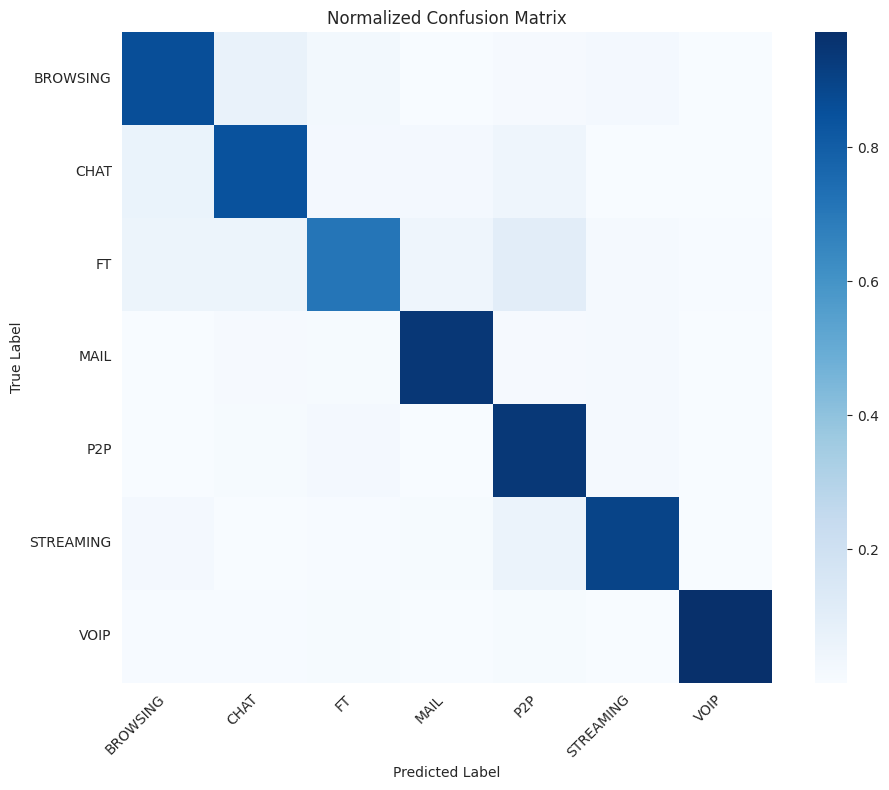

In [14]:
# Confusion Matrix Heatmap

plt.figure(figsize=(10, 8))
sns.heatmap(cm_df, annot=False, cmap="Blues", cbar=True, square=True)
plt.title("Normalized Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

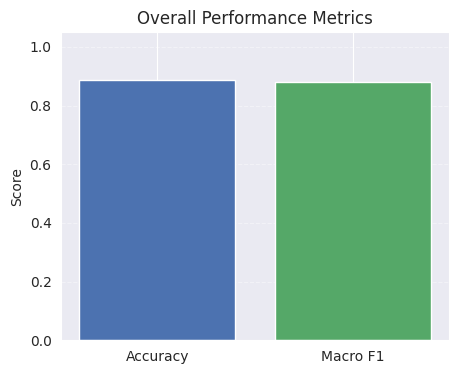

In [15]:
plt.figure(figsize=(5, 4))
plt.bar(["Accuracy", "Macro F1"], [test_acc, test_f1], color=["#4c72b0", "#55a868"])
plt.ylim(0, 1.05)
plt.title("Overall Performance Metrics")
plt.ylabel("Score")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.show()

In [16]:
class TemperatureScaler(nn.Module):
    def __init__(self):
        super().__init__()
        self.log_t = nn.Parameter(torch.zeros(1))
    def forward(self, logits):
        return logits / torch.exp(self.log_t)

@torch.no_grad()
def collect_val_logits(model, loader):
    model.eval()
    L, Y = [], []
    for xb, yb in loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        out = model(xb)
        logits = get_logits(out)
        L.append(logits)
        Y.append(yb)
    return torch.cat(L), torch.cat(Y)

def calibrate_temperature(model, val_loader):
    model.eval()
    temp = TemperatureScaler().to(DEVICE)
    opt = torch.optim.LBFGS(temp.parameters(), lr=0.1, max_iter=50)
    nll = nn.CrossEntropyLoss()
    logits_all, labels_all = collect_val_logits(model, val_loader)
    def closure():
        opt.zero_grad()
        loss = nll(temp(logits_all), labels_all)
        loss.backward()
        return loss
    opt.step(closure)
    return temp

temp = calibrate_temperature(model, val_loader)
print(f"calibrated_T={float(torch.exp(temp.log_t)):.4f}")

calibrated_T=0.7621


In [17]:
def ece_score(probs_np, y_true_np, bins=15):
    if len(probs_np) == 0:
        return 0.0
    conf = probs_np.max(axis=1)
    pred = probs_np.argmax(axis=1)
    correct = (pred == y_true_np).astype(float)
    edges = np.linspace(0.0, 1.0, bins + 1)
    ece = 0.0
    for i in range(bins):
        m = (conf >= edges[i]) & (conf < (edges[i+1] if i < bins-1 else edges[i+1]))
        if not np.any(m):
            continue
        ece += (m.mean()) * abs(correct[m].mean() - conf[m].mean())
    return float(ece)

@torch.no_grad()
def sweep_thresholds(
    model, temp, loader,
    taus=np.linspace(0.4, 0.9, 11),
    margins=(0.0, 0.05, 0.10, 0.20),
    ents=(np.inf, 2.0, 1.5, 1.0)
):
    model.eval()
    dev = next(model.parameters()).device
    H = torch.distributions.Categorical
    y_true, y_pred, probs_list, maxp_list, margin_list, ent_list = [], [], [], [], [], []
    for xb, yb in loader:
        xb = xb.to(dev)
        logits = temp(get_logits(model(xb)))
        probs = torch.softmax(logits, dim=1)
        top2 = torch.topk(probs, k=2, dim=1).values
        maxp = top2[:, 0]
        margin = (top2[:, 0] - top2[:, 1])
        ent = H(probs=probs).entropy().clamp_min_(0)
        y_true.append(yb.cpu().numpy())
        y_pred.append(probs.argmax(1).cpu().numpy())
        probs_list.append(probs.cpu().numpy())
        maxp_list.append(maxp.cpu().numpy())
        margin_list.append(margin.cpu().numpy())
        ent_list.append(ent.cpu().numpy())
    y_true = np.concatenate(y_true)
    y_pred = np.concatenate(y_pred)
    probsNP = np.concatenate(probs_list)
    maxp = np.concatenate(maxp_list)
    margin = np.concatenate(margin_list)
    entropy = np.concatenate(ent_list)
    rows = []
    for tau in taus:
        for m in margins:
            for e in ents:
                accept = (maxp >= tau) & (margin >= m) & (entropy <= e)
                cov = float(accept.mean())
                if cov > 0:
                    y_a = y_true[accept]
                    yhat_a = y_pred[accept]
                    probs_a = probsNP[accept]
                    macroF1 = f1_score(y_a, yhat_a, average="macro", zero_division=0)
                    microF1 = f1_score(y_a, yhat_a, average="micro", zero_division=0)
                    acc = accuracy_score(y_a, yhat_a)
                    ece = ece_score(probs_a, y_a, bins=15)
                else:
                    macroF1 = microF1 = acc = ece = 0.0
                rows.append((tau, m, e, cov, macroF1, microF1, acc, ece))
    df = pd.DataFrame(rows, columns=["tau","margin","entropy_max","coverage","macroF1","microF1","accuracy","ECE"])
    df = df.sort_values("macroF1", ascending=False).reset_index(drop=True)
    return df

def pick_thresholds(df, target_coverage=0.70):
    hit = df[df.coverage >= target_coverage].copy()
    if len(hit) == 0:
        df["gap"] = (df.coverage - target_coverage).abs()
        hit = df.sort_values(["gap","macroF1"], ascending=[True, False]).head(1)
    best = hit.sort_values(["macroF1","ECE"], ascending=[False, True]).iloc[0]
    return dict(tau=float(best.tau), margin=float(best.margin),
                entropy_max=float(best.entropy_max), coverage=float(best.coverage))

grid = sweep_thresholds(model, temp, val_loader)
choice = pick_thresholds(grid, target_coverage=0.70)

TAU = float(choice["tau"])
MARGIN = float(choice["margin"])
ENTROPY_MAX = float(choice["entropy_max"])
target_coverage = float(choice["coverage"])

HARD_TAU = float(max(TAU, 0.95))
hard_tau = HARD_TAU
hard_ent = ENTROPY_MAX
hard_margin = MARGIN

ROUTE_TAU = float(TAU - 0.05 if TAU >= 0.05 else 0.0)
ROUTE_MARGIN = float(MARGIN * 0.8)
ROUTE_ENTROPY = float(ENTROPY_MAX)

lambda_cov = 2.5
R_TP = 1.5
R_FP = -2.5
R_RH = 0.4
R_RE = -1.5

USE_POLICY = True
HARD_GATE_AFTER_POLICY = True

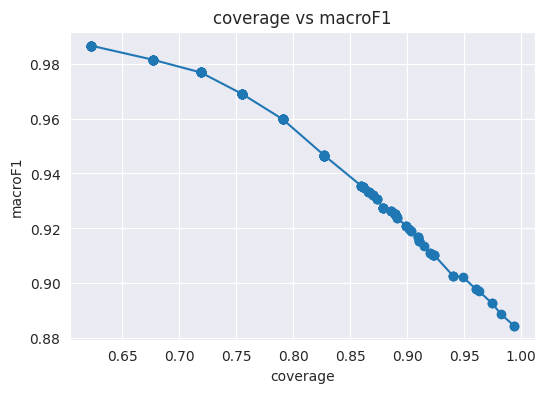

In [18]:
plt.figure(figsize=(6,4))
plt.plot(grid["coverage"], grid["macroF1"], "o-")
plt.xlabel("coverage")
plt.ylabel("macroF1")
plt.title("coverage vs macroF1")
plt.grid(True)
plt.show()

In [19]:
class RLDecisionLayer(nn.Module):
    def __init__(self, in_dim, hidden=64):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(in_dim, hidden), nn.ReLU(), nn.Linear(hidden, 2))
    def forward(self, s):
        return self.net(s)

@torch.no_grad()
def _forward_backbone(model, temp, xb):
    logits = temp(get_logits(model(xb)))
    probs = torch.softmax(logits, dim=1)
    top2 = torch.topk(probs, k=2, dim=1).values
    max_p = top2[:, :1]
    margin = (top2[:,0] - top2[:,1]).unsqueeze(1)
    ent = torch.distributions.Categorical(probs=probs).entropy().unsqueeze(1)
    state = torch.cat([probs, max_p, ent, margin], dim=1)
    pred = probs.argmax(dim=1)
    return state, probs, pred, max_p, ent, margin

@torch.no_grad()
def _apply_overrides(probs, ent, action, tau, margin, hard_tau, route_tau, route_margin, route_entropy):
    top2 = torch.topk(probs, k=2, dim=1).values
    m_p = top2[:, 0]
    m_g = (top2[:, 0] - top2[:, 1]).clamp_min_(0)
    must_route = (m_p < route_tau) | (m_g < route_margin) | (ent.squeeze(1) > route_entropy)
    accept = (m_p >= tau) & (m_g >= margin)
    hard_accept = (m_p >= hard_tau)
    action = torch.where(must_route, torch.ones_like(action), action)
    action = torch.where(accept, torch.zeros_like(action), action)
    action = torch.where(hard_accept, torch.zeros_like(action), action)
    return action

@torch.no_grad()
def evaluate_rl(model, temp, policy, loader, device=None,
                tau=None, margin=None, hard_tau=None, route_tau=None, route_margin=None, route_entropy=None):
    model.eval(); policy.eval()
    dev = device or next(model.parameters()).device
    y_true_all, y_pred_all, act_all = [], [], []
    for xb, yb in loader:
        xb, yb = xb.to(dev), yb.to(dev)
        logits = temp(get_logits(model(xb)))
        probs = torch.softmax(logits, dim=1)
        top2 = torch.topk(probs, k=2, dim=1).values
        max_p = top2[:, :1]
        margin_t = (top2[:,0] - top2[:,1]).unsqueeze(1)
        ent = torch.distributions.Categorical(probs=probs).entropy().unsqueeze(1)
        state = torch.cat([probs, max_p, ent, margin_t], dim=1)
        logpi = policy(state)
        action = torch.argmax(logpi, dim=1)
        action = _apply_overrides(
            probs, ent, action,
            tau if tau is not None else TAU,
            margin if margin is not None else MARGIN,
            hard_tau if hard_tau is not None else HARD_TAU,
            route_tau if route_tau is not None else ROUTE_TAU,
            route_margin if route_margin is not None else ROUTE_MARGIN,
            route_entropy if route_entropy is not None else ROUTE_ENTROPY
        )
        pred = probs.argmax(dim=1)
        y_true_all.append(yb.cpu().numpy())
        y_pred_all.append(pred.cpu().numpy())
        act_all.append(action.cpu().numpy())
    y_true = np.concatenate(y_true_all)
    y_pred = np.concatenate(y_pred_all)
    actions = np.concatenate(act_all)
    accepted = (actions == 0)
    coverage = accepted.mean()
    macroF1 = f1_score(y_true[accepted], y_pred[accepted], average="macro") if coverage > 0 else 0.0
    return dict(coverage=coverage, macroF1=macroF1)



In [20]:
def train_rl_offline(
    model, temp, rl_train_loader, rl_val_loader,
    hard_tau, hard_ent, hard_margin,
    target_coverage, lambda_cov,
    R_TP, R_FP, R_RH, R_RE,
    epochs=20, lr=1e-3, grad_clip=2.0, ent_bonus=0.02, ema_cov=0.9
):
    model.eval(); temp.eval()
    dev = next(model.parameters()).device
    in_dim = len(classes) + 3
    policy = RLDecisionLayer(in_dim=in_dim, hidden=64).to(dev)
    opt = torch.optim.Adam(policy.parameters(), lr=lr)
    ema_R = None
    ema_cov_now = target_coverage
    hist = {"epoch": [], "loss": [], "meanR": [], "stdR": [], "val_cov": [], "val_macroF1": []}
    for ep in range(1, epochs + 1):
        policy.train()
        logp_all, R_all, H_all = [], [], []
        for xb, yb in rl_train_loader:
            xb, yb = xb.to(dev), yb.to(dev)
            with torch.no_grad():
                logits = temp(get_logits(model(xb)))
                probs = torch.softmax(logits, dim=1)
                top2 = torch.topk(probs, k=2, dim=1).values
                max_p = top2[:, :1]
                margin_t = (top2[:,0] - top2[:,1]).unsqueeze(1)
                ent = torch.distributions.Categorical(probs=probs).entropy().unsqueeze(1)
                state = torch.cat([probs, max_p, ent, margin_t], dim=1)
                pred = probs.argmax(dim=1)
            logits_pi = policy(state)
            dist = torch.distributions.Categorical(logits=logits_pi)
            action_raw = dist.sample()
            logp_a = dist.log_prob(action_raw)
            H_pi = dist.entropy()
            with torch.no_grad():
                correct = (pred == yb).float()
                hard_flag = ((max_p.squeeze(1) < hard_tau) | (ent.squeeze(1) > hard_ent) | (margin_t.squeeze(1) < hard_margin)).float()
                reward_classify = torch.where(correct == 1, torch.tensor(R_TP, device=dev), torch.tensor(R_FP, device=dev))
                reward_route = torch.where(hard_flag == 1, torch.tensor(R_RH, device=dev), torch.tensor(R_RE, device=dev))
                action = _apply_overrides(
                    probs, ent, action_raw,
                    TAU, MARGIN, hard_tau, ROUTE_TAU, ROUTE_MARGIN, ROUTE_ENTROPY
                )
                batch_cov = 1.0 - (action == 1).float().mean().item()
                ema_cov_now = ema_cov * ema_cov_now + (1 - ema_cov) * batch_cov
                cov_gap = (target_coverage - ema_cov_now)
                reward = torch.where(action == 0, reward_classify + lambda_cov * cov_gap, reward_route - lambda_cov * cov_gap).detach()
            logp_all.append(logp_a)
            R_all.append(reward)
            H_all.append(H_pi)
        logp_all = torch.cat(logp_all)
        R_all = torch.cat(R_all)
        H_all = torch.cat(H_all)
        meanR = R_all.mean().item()
        stdR = R_all.std().item() + 1e-8
        if ema_R is None:
            ema_R = meanR
        else:
            ema_R = 0.9 * ema_R + 0.1 * meanR
        advantage = (R_all - torch.tensor(ema_R, device=R_all.device)).detach() / stdR
        loss = -(logp_all * advantage).mean() - 0.02 * H_all.mean()
        opt.zero_grad(set_to_none=True)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(policy.parameters(), grad_clip)
        opt.step()
        m = evaluate_rl(
            model, temp, policy, rl_val_loader, device=dev,
            tau=TAU, margin=MARGIN, hard_tau=hard_tau,
            route_tau=ROUTE_TAU, route_margin=ROUTE_MARGIN, route_entropy=ROUTE_ENTROPY
        )
        hist["epoch"].append(ep)
        hist["loss"].append(float(loss.item()))
        hist["meanR"].append(float(meanR))
        hist["stdR"].append(float(stdR))
        hist["val_cov"].append(float(m["coverage"]))
        hist["val_macroF1"].append(float(m["macroF1"]))
        print(f"epoch={ep:03d} loss={loss.item():.4f} val_cov={m['coverage']:.3f} val_macroF1={m['macroF1']:.4f}")
    policy.eval()
    return policy, hist


In [21]:
policy, hist = train_rl_offline(
    model, temp, train_loader, val_loader,
    hard_tau=hard_tau, hard_ent=hard_ent, hard_margin=hard_margin,
    target_coverage=target_coverage, lambda_cov=lambda_cov,
    R_TP=R_TP, R_FP=R_FP, R_RH=R_RH, R_RE=R_RE,
    epochs=10, lr=1e-3, ent_bonus=0.01
)

metrics = evaluate_rl(model, temp, policy, val_loader)
print(f"final_val_macroF1={metrics['macroF1']:.4f} final_val_coverage={metrics['coverage']:.3f}")


epoch=001 loss=-0.0127 val_cov=0.720 val_macroF1=0.9762
epoch=002 loss=-0.0162 val_cov=0.722 val_macroF1=0.9756
epoch=003 loss=-0.0148 val_cov=0.729 val_macroF1=0.9745
epoch=004 loss=-0.0147 val_cov=0.738 val_macroF1=0.9718
epoch=005 loss=-0.0150 val_cov=0.745 val_macroF1=0.9709
epoch=006 loss=-0.0159 val_cov=0.748 val_macroF1=0.9700
epoch=007 loss=-0.0160 val_cov=0.749 val_macroF1=0.9698
epoch=008 loss=-0.0171 val_cov=0.749 val_macroF1=0.9698
epoch=009 loss=-0.0170 val_cov=0.749 val_macroF1=0.9697
epoch=010 loss=-0.0163 val_cov=0.750 val_macroF1=0.9696
final_val_macroF1=0.9696 final_val_coverage=0.750


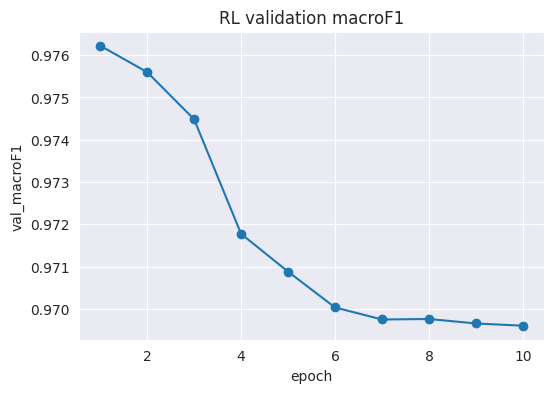

In [22]:
plt.figure(figsize=(6,4))
plt.plot(hist["epoch"], hist["val_macroF1"], "-o")
plt.xlabel("epoch"); plt.ylabel("val_macroF1"); plt.title("RL validation macroF1"); plt.grid(True); plt.show()


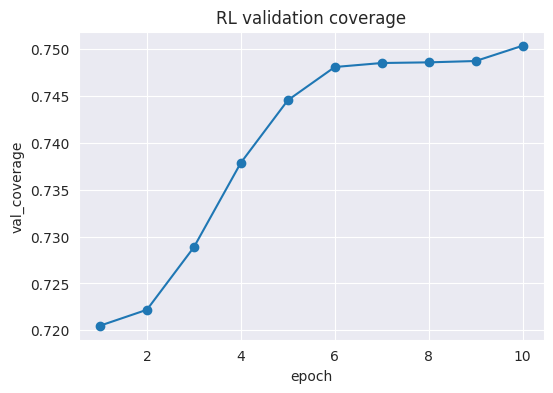

In [23]:
plt.figure(figsize=(6,4))
plt.plot(hist["epoch"], hist["val_cov"], "-o")
plt.xlabel("epoch")
plt.ylabel("val_coverage")
plt.title("RL validation coverage")
plt.grid(True)
plt.show()


In [24]:
@torch.no_grad()
def build_state_from_logits(logits):
    probs = torch.softmax(logits, dim=1)
    top2 = torch.topk(probs, k=2, dim=1).values
    max_p = top2[:, :1]
    margin = (top2[:, 0] - top2[:, 1]).unsqueeze(1)
    ent = -(probs * (probs.clamp_min(1e-9)).log()).sum(dim=1, keepdim=True)
    state = torch.cat([probs, max_p, ent, margin], dim=1)
    return state, probs, max_p, ent, margin

@torch.no_grad()
def rl_decide(model, temp, policy, xb):
    dev = next(model.parameters()).device
    xb = xb.to(dev)
    out = model(xb)
    logits = temp(get_logits(out))
    state, probs, max_p, ent, margin = build_state_from_logits(logits)
    if USE_POLICY:
        logpi = policy(state)
        action = torch.argmax(logpi, dim=1)
    else:
        action = torch.ones((xb.size(0),), dtype=torch.long, device=dev)
    top2 = torch.topk(probs, k=2, dim=1).values
    m_p = top2[:, 0]
    m_g = (top2[:, 0] - top2[:, 1]).clamp_min_(0)
    hard_accept = (m_p >= HARD_TAU)
    accept = (m_p >= TAU) & (m_g >= MARGIN)
    must_route = (m_p < ROUTE_TAU) | (m_g < ROUTE_MARGIN) | (ent.squeeze(1) > ROUTE_ENTROPY)
    action = torch.where(must_route, torch.ones_like(action), action)
    action = torch.where(accept, torch.zeros_like(action), action)
    action = torch.where(hard_accept, torch.zeros_like(action), action)
    pred = probs.argmax(dim=1)
    emb = out[1] if isinstance(out, (tuple, list)) else None
    return action, pred, probs, emb

acts, preds, trues, routed_embs = [], [], [], []
model.eval()
with torch.no_grad():
    for xb, yb in test_loader:
        action, pred, probs, emb = rl_decide(model, temp, policy, xb)
        trues.append(yb.cpu().numpy())
        preds.append(pred.cpu().numpy())
        acts.append(action.cpu().numpy())
        if emb is not None:
            take = (action == 1)
            if take.any():
                routed_embs.append(emb[take].cpu().numpy())
y_true = np.concatenate(trues)
y_pred = np.concatenate(preds)
actions = np.concatenate(acts)
coverage_test = (actions == 0).mean()
print(f"test_coverage={coverage_test:.3f}")


routed_embs = np.vstack(routed_embs) if len(routed_embs) else np.empty((0,128))

model.eval()
all_actions, all_preds = [], []
routed_embs = []

with torch.no_grad():
    for xb, yb in val_loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        action, pred, probs, emb = rl_decide(model, temp, policy, xb)
        all_actions.append(action.cpu().numpy())
        all_preds.append(pred.cpu().numpy())
        if emb is not None:
            take = (action == 1)
            if take.any():
                routed_embs.append(emb[take].cpu().numpy())

all_actions = np.concatenate(all_actions)
all_preds   = np.concatenate(all_preds)
routed_rate = (all_actions == 1).mean()
print(f"Routed fraction: {routed_rate:.3f}")

if len(routed_embs):
    routed_embs = np.vstack(routed_embs)
    print("Routed embeddings shape:", routed_embs.shape)
else:
    routed_embs = np.empty((0,128))

test_coverage=0.744
Routed fraction: 0.250
Routed embeddings shape: (3513, 128)


In [25]:
def cluster_unknowns(embeddings, eps=0.7, min_samples=20):
    if len(embeddings) == 0:
        return np.array([])
    Z = StandardScaler().fit_transform(embeddings)
    db = DBSCAN(eps=eps, min_samples=min_samples, metric="euclidean").fit(Z)
    return db.labels_

labels = cluster_unknowns(routed_embs, eps=0.7, min_samples=20)
if labels.size:
    vals, cnts = np.unique(labels, return_counts=True)
    print("cluster_labels", dict(zip(vals.tolist(), cnts.tolist())))
else:
    print("cluster_labels {}")

cluster_labels {-1: 2571, 0: 489, 1: 54, 2: 29, 3: 160, 4: 49, 5: 36, 6: 73, 7: 32, 8: 20}


In [26]:
accepted_mask = (all_actions == 0)
coverage = accepted_mask.mean()
print(f"Coverage (accepted %): {coverage:.3f}")

y_true_val = []
with torch.no_grad():
    for _, yb in val_loader:
        y_true_val.append(yb.cpu().numpy())
y_true_val = np.concatenate(y_true_val)

f1_on_accepted = f1_score(y_true_val[accepted_mask], all_preds[accepted_mask], average="macro") if coverage>0 else 0.0
print(f"Macro-F1 on accepted set: {f1_on_accepted:.4f}")


Coverage (accepted %): 0.750
Macro-F1 on accepted set: 0.9696


share_hard_accept=0.544 share_accept=0.175 share_must_route=0.245 share_policy_zone=0.037
coverage=0.750 acc_on_accepted=0.9724 acc_on_policy_zone=0.8180


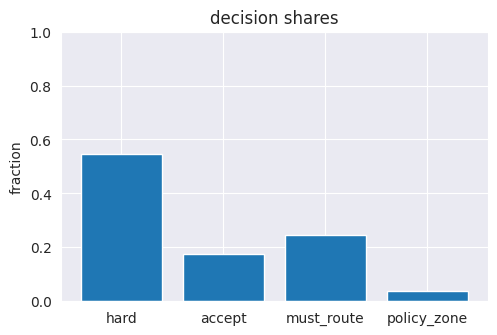

In [27]:
@torch.no_grad()
def decision_breakdown(model, temp, policy, loader):
    dev = next(model.parameters()).device
    N = 0
    c_hard, c_accept, c_mustr, c_policy = 0,0,0,0
    acc_overall_num, acc_overall_den = 0,0
    acc_policy_num,  acc_policy_den  = 0,0
    for xb, yb in loader:
        xb, yb = xb.to(dev), yb.to(dev)
        logits = temp(get_logits(model(xb)))
        probs = torch.softmax(logits, dim=1)
        top2 = torch.topk(probs, k=2, dim=1).values
        m_p = top2[:,0]
        m_g = (top2[:,0]-top2[:,1]).clamp_min_(0)
        ent = torch.distributions.Categorical(probs=probs).entropy().unsqueeze(1)
        state = torch.cat([probs, top2[:,:1], ent, (top2[:,0]-top2[:,1]).unsqueeze(1)], dim=1)
        a = torch.argmax(policy(state), dim=1)
        hard_accept = (m_p >= HARD_TAU)
        accept = (m_p >= TAU) & (m_g >= MARGIN)
        must_route = (m_p < ROUTE_TAU) | (m_g < ROUTE_MARGIN) | (ent.squeeze(1) > ROUTE_ENTROPY)
        mask_hard = hard_accept
        mask_acc  = accept & (~hard_accept)
        mask_mr   = must_route & (~accept) & (~hard_accept)
        mask_pol  = (~must_route) & (~accept) & (~hard_accept)
        a = torch.where(must_route, torch.ones_like(a), a)
        a = torch.where(accept,      torch.zeros_like(a), a)
        a = torch.where(hard_accept, torch.zeros_like(a), a)
        pred = probs.argmax(1)
        N += xb.size(0)
        c_hard += mask_hard.sum().item()
        c_accept += mask_acc.sum().item()
        c_mustr += mask_mr.sum().item()
        c_policy += mask_pol.sum().item()
        take = (a==0)
        acc_overall_num += (pred[take]==yb[take]).sum().item()
        acc_overall_den += take.sum().item()
        take_pol = (take & mask_pol)
        acc_policy_num += (pred[take_pol]==yb[take_pol]).sum().item()
        acc_policy_den += take_pol.sum().item()
    frac = np.array([c_hard, c_accept, c_mustr, c_policy], dtype=float)/max(N,1)
    print(f"share_hard_accept={frac[0]:.3f} share_accept={frac[1]:.3f} share_must_route={frac[2]:.3f} share_policy_zone={frac[3]:.3f}")
    cov = acc_overall_den/max(N,1)
    acc_overall = acc_overall_num/max(acc_overall_den,1)
    acc_policy  = acc_policy_num/max(acc_policy_den,1) if acc_policy_den>0 else float('nan')
    print(f"coverage={cov:.3f} acc_on_accepted={acc_overall:.4f} acc_on_policy_zone={acc_policy:.4f}")
    plt.figure(figsize=(5.5,3.5))
    plt.bar(["hard","accept","must_route","policy_zone"], frac)
    plt.ylim(0,1); plt.title("decision shares"); plt.ylabel("fraction"); plt.grid(True, axis="y"); plt.show()
    return {"shares": frac, "coverage": cov, "acc_acc": acc_overall, "acc_policy": acc_policy}

bd = decision_breakdown(model, temp, policy, val_loader)


gate_eval coverage=0.750 macroF1=0.9696
gate_eval coverage=0.778 macroF1=0.9611


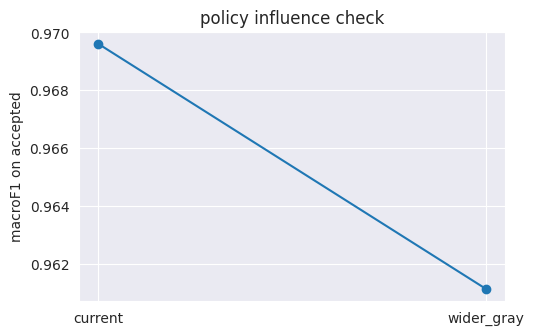

In [28]:
TAU_alt = TAU + 0.02
ROUTE_TAU_alt = max(0.0, ROUTE_TAU - 0.05)
MARGIN_alt = MARGIN
ROUTE_MARGIN_alt = max(0.0, ROUTE_MARGIN * 0.9)
ROUTE_ENTROPY_alt = ROUTE_ENTROPY

@torch.no_grad()
def evaluate_with_gate(model, temp, policy, loader,
                       TAU_g, MARGIN_g, HARD_TAU_g, ROUTE_TAU_g, ROUTE_MARGIN_g, ROUTE_ENTROPY_g):
    dev = next(model.parameters()).device
    y_true_all, y_pred_all, act_all = [], [], []
    for xb, yb in loader:
        xb, yb = xb.to(dev), yb.to(dev)
        logits = temp(get_logits(model(xb)))
        probs = torch.softmax(logits, dim=1)
        top2 = torch.topk(probs, k=2, dim=1).values
        m_p = top2[:,0]
        m_g = (top2[:,0]-top2[:,1]).clamp_min_(0)
        ent = torch.distributions.Categorical(probs=probs).entropy().unsqueeze(1)
        state = torch.cat([probs, top2[:,:1], ent, (top2[:,0]-top2[:,1]).unsqueeze(1)], dim=1)
        a = torch.argmax(policy(state), dim=1)
        must_route = (m_p < ROUTE_TAU_g) | (m_g < ROUTE_MARGIN_g) | (ent.squeeze(1) > ROUTE_ENTROPY_g)
        accept = (m_p >= TAU_g) & (m_g >= MARGIN_g)
        hard_accept = (m_p >= HARD_TAU_g)
        a = torch.where(must_route, torch.ones_like(a), a)
        a = torch.where(accept, torch.zeros_like(a), a)
        a = torch.where(hard_accept, torch.zeros_like(a), a)
        pred = probs.argmax(1)
        y_true_all.append(yb.cpu().numpy())
        y_pred_all.append(pred.cpu().numpy())
        act_all.append(a.cpu().numpy())
    y_true = np.concatenate(y_true_all)
    y_pred = np.concatenate(y_pred_all)
    actions = np.concatenate(act_all)
    accepted = (actions==0)
    cov = accepted.mean()
    macroF1 = f1_score(y_true[accepted], y_pred[accepted], average="macro") if cov>0 else 0.0
    print(f"gate_eval coverage={cov:.3f} macroF1={macroF1:.4f}")
    return cov, macroF1

cov0, f10 = evaluate_with_gate(model, temp, policy, val_loader, TAU, MARGIN, HARD_TAU, ROUTE_TAU, ROUTE_MARGIN, ROUTE_ENTROPY)
cov1, f11 = evaluate_with_gate(model, temp, policy, val_loader, TAU_alt, MARGIN_alt, HARD_TAU, ROUTE_TAU_alt, ROUTE_MARGIN_alt, ROUTE_ENTROPY_alt)

plt.figure(figsize=(5.5,3.5))
plt.plot([0,1],[f10,f11],"o-")
plt.xticks([0,1],["current","wider_gray"])
plt.ylabel("macroF1 on accepted"); plt.title("policy influence check"); plt.grid(True); plt.show()


In [29]:
models_dir = ART_DIR / "models"
logs_dir = ART_DIR / "logs"
models_dir.mkdir(parents=True, exist_ok=True)
logs_dir.mkdir(parents=True, exist_ok=True)

cnn_path  = models_dir / "cnn_final.pt"
temp_path = models_dir / "temp_calibrator.pt"
rl_path   = models_dir / "rl_policy.pt"

torch.save(model.state_dict(), cnn_path)
torch.save(temp.state_dict(), temp_path)
torch.save(policy.state_dict(), rl_path)

print(f"Saved CNN to: {cnn_path}")
print(f"Saved TempCalibrator to: {temp_path}")
print(f"Saved RL Policy to: {rl_path}")

idx_train_path = ART_DIR/"logs"/"split_idx_train.npy"
idx_val_path   = ART_DIR/"logs"/"split_idx_val.npy"
idx_test_path  = ART_DIR/"logs"/"split_idx_test.npy"

rl_epochs = int(len(hist["epoch"])) if "hist" in locals() else 0
seed_val = int(SEED) if "SEED" in globals() else 42

manifest = {
    "versions": {
        "torch": torch.__version__,
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "imblearn": "imblearn"
    },
    "device": str(DEVICE),
    "artifacts": {
        "cnn_state_dict": str(cnn_path),
        "temp_state_dict": str(temp_path),
        "rl_policy": str(rl_path),
        "label_encoder": str(ART_DIR/"label_encoder.joblib"),
        "label_classes": str(ART_DIR/"label_classes.npy"),
        "shiftlog_params": str(ART_DIR/"scalers"/"shiftlog_params.joblib"),
        "imputer": str(ART_DIR/"scalers"/"imputer_median.joblib"),
        "variance_threshold": str(ART_DIR/"scalers"/"variance_threshold.joblib"),
        "robust_scaler": str(ART_DIR/"scalers"/"robust_scaler.joblib"),
        "standard_scaler": str(ART_DIR/"scalers"/"standard_scaler.joblib"),
        "kept_features": str(ART_DIR/"kept_features.json"),
        "corr_dropped": str(ART_DIR/"corr_dropped.json"),
        "train_feature_cols": str(ART_DIR/"logs"/"train_feature_cols.json"),
        "train_history": str(ART_DIR/"logs"/"train_history.csv"),
        "split_idx_train": str(idx_train_path),
        "split_idx_val":   str(idx_val_path),
        "split_idx_test":  str(idx_test_path)
    },
    "notes": {
        "resampling": "SMOTE",
        "loss": "FocalLoss(gamma=1.5, alpha=class_weights)"
    }
}

manifest["rl_config"] = {
    "reward_table": {
        "R_TP": float(R_TP),
        "R_FP": float(R_FP),
        "R_RH": float(R_RH),
        "R_RE": float(R_RE)
    },
    "coverage": {
        "target_coverage": float(target_coverage),
        "lambda_cov": float(lambda_cov),
        "penalty": "linear"
    },
    "splits": {"rl_train": "train", "rl_val": "val"},
    "epochs": rl_epochs
}

manifest["runtime"] = {
    "accept_thresholds": {
        "TAU": float(TAU),
        "MARGIN": float(MARGIN),
        "HARD_TAU": float(HARD_TAU)
    },
    "route_thresholds": {
        "ENTROPY_MAX": float(ENTROPY_MAX),
        "ROUTE_TAU": float(ROUTE_TAU),
        "ROUTE_MARGIN": float(ROUTE_MARGIN),
        "ROUTE_ENTROPY": float(ROUTE_ENTROPY)
    },
    "use_policy": bool(USE_POLICY),
    "hard_gate_after_policy": True
}

manifest["model_config"] = {
    "arch": "FeatureCNN_Attn",
    "widths": [128, 256],
    "attention": {"embed_dim": 256, "num_heads": 4, "dropout": 0.35},
    "embedding_dim": 128,
    "dropout": 0.35,
    "n_feats": int(len(json.load(open(ART_DIR/'kept_features.json')))),
    "n_classes": int(len(np.load(ART_DIR/'label_classes.npy', allow_pickle=True)))
}

manifest["resampling_detail"] = {
    "method": "SMOTE",
    "cap_per_class_preview": 10000,
    "random_state": seed_val
}



mn_path = logs_dir / "artifacts_manifest.json"
with open(mn_path, "w") as f:
    json.dump(manifest, f, indent=2)
print(f"Saved manifest at: {mn_path}")

with open(mn_path, "r") as f:
    mchk = json.load(f)
print(f"runtime_accept={mchk['runtime']['accept_thresholds']} runtime_route={mchk['runtime']['route_thresholds']}")


Saved CNN to: /mnt/d/FYP/RLFINALFINAL/deepv14/models/cnn_final.pt
Saved TempCalibrator to: /mnt/d/FYP/RLFINALFINAL/deepv14/models/temp_calibrator.pt
Saved RL Policy to: /mnt/d/FYP/RLFINALFINAL/deepv14/models/rl_policy.pt
Saved manifest at: /mnt/d/FYP/RLFINALFINAL/deepv14/logs/artifacts_manifest.json
runtime_accept={'TAU': 0.8, 'MARGIN': 0.0, 'HARD_TAU': 0.95} runtime_route={'ENTROPY_MAX': inf, 'ROUTE_TAU': 0.75, 'ROUTE_MARGIN': 0.0, 'ROUTE_ENTROPY': inf}
